In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/metablocking/D2/'

In [2]:
df_cep = pd.read_csv(main_dir + 'CardinalityEdgePruning_12.csv')
df_cep['algorithm'] = 'cep'
df_cnp = pd.read_csv(main_dir + 'CardinalityNodePruning_12.csv')
df_cnp['algorithm'] = 'cnp'
df_wep = pd.read_csv(main_dir + 'WeightedEdgePruning_12.csv')
df_wep['algorithm'] = 'wep'
df_wnp = pd.read_csv(main_dir + 'WeightedNodePruning_12.csv')
df_wnp['algorithm'] = 'wnp'

In [3]:
result = pd.DataFrame()
dfs = [df_cep, df_cnp, df_wep, df_wnp]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,candidate_pairs,adjacent_bits,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,algorithm,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,CardinalityEdgePruning,92020,12,1.15,99.44,2.27,1058,90962,1070,6,cep,[name],1024,0,1,salted_qgrams,,4
1,CardinalityEdgePruning,92020,12,1.15,99.34,2.27,1057,90963,1069,7,cep,[name],1024,0,2,salted_qgrams,,4
2,CardinalityEdgePruning,92020,12,1.14,98.40,2.25,1047,90973,1059,17,cep,[name],1024,0,3,salted_qgrams,,4
3,CardinalityEdgePruning,92020,12,1.13,97.46,2.23,1037,90983,1049,27,cep,[name],1024,0,4,salted_qgrams,,4
4,CardinalityEdgePruning,92020,12,1.11,96.43,2.20,1026,90994,1038,38,cep,[name],1024,0,6,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123,WeightedNodePruning,23435,12,3.45,76.03,6.60,809,22626,821,255,wnp,[name],1024,0,29,salted_qgrams,,4
124,WeightedNodePruning,13718,12,5.83,75.19,10.82,800,12918,812,264,wnp,[name],1024,0,26,salted_qgrams,,4
125,WeightedNodePruning,28874,12,2.81,76.32,5.42,812,28062,824,252,wnp,[name],1024,0,30,salted_qgrams,,4
126,WeightedNodePruning,35970,12,2.29,77.44,4.45,824,35146,836,240,wnp,[name],1024,0,31,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[name]    128
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    128
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    128
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    128
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    128
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     4
2     4
3     4
4     4
6     4
5     4
7     4
8     4
10    4
9     4
11    4
14    4
13    4
16    4
12    4
15    4
18    4
19    4
21    4
24    4
20    4
22    4
23    4
17    4
28    4
29    4
25    4
30    4
27    4
26    4
31    4
32    4
Name: count, dtype: int64

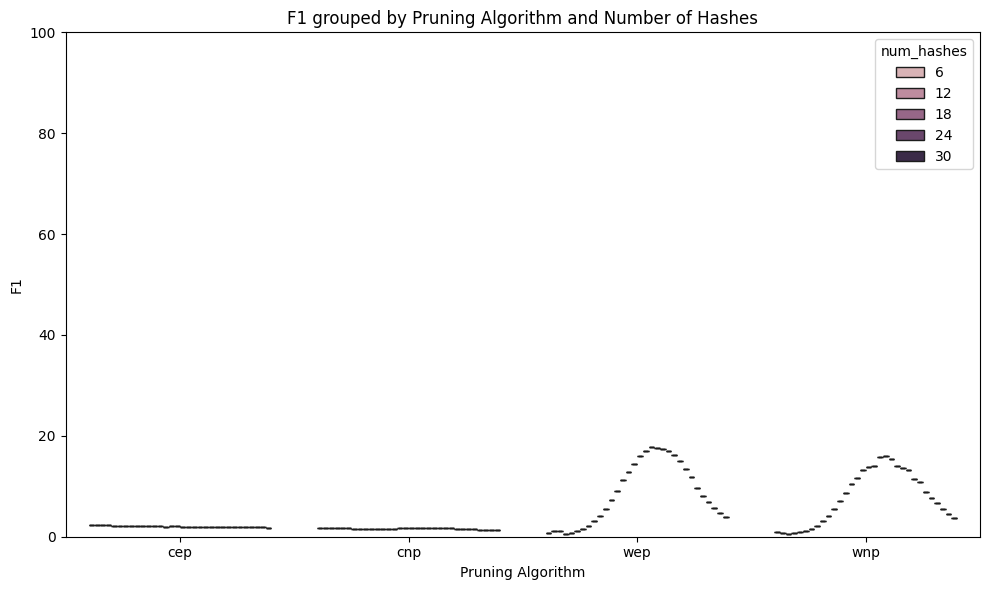

In [10]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=result,
    x="algorithm",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Pruning Algorithm and Number of Hashes")
plt.xlabel("Pruning Algorithm")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [11]:
metrics_df = result.melt(
    id_vars=["algorithm", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,algorithm,num_hashes,Metric,Score
0,cep,1,Precision %,1.15
1,cep,2,Precision %,1.15
2,cep,3,Precision %,1.14
3,cep,4,Precision %,1.13
4,cep,6,Precision %,1.11
...,...,...,...,...
379,wnp,29,F1 %,6.60
380,wnp,26,F1 %,10.82
381,wnp,30,F1 %,5.42
382,wnp,31,F1 %,4.45


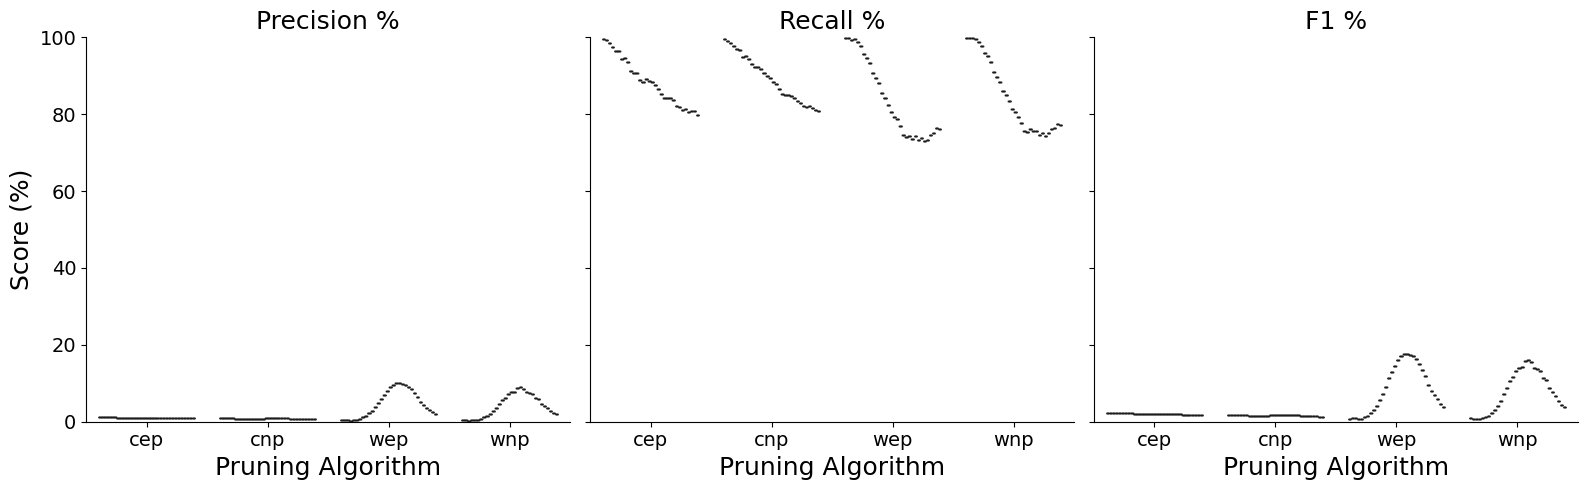

In [12]:
g = sns.catplot(
    data=metrics_df,
    x="algorithm",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Pruning Algorithm", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

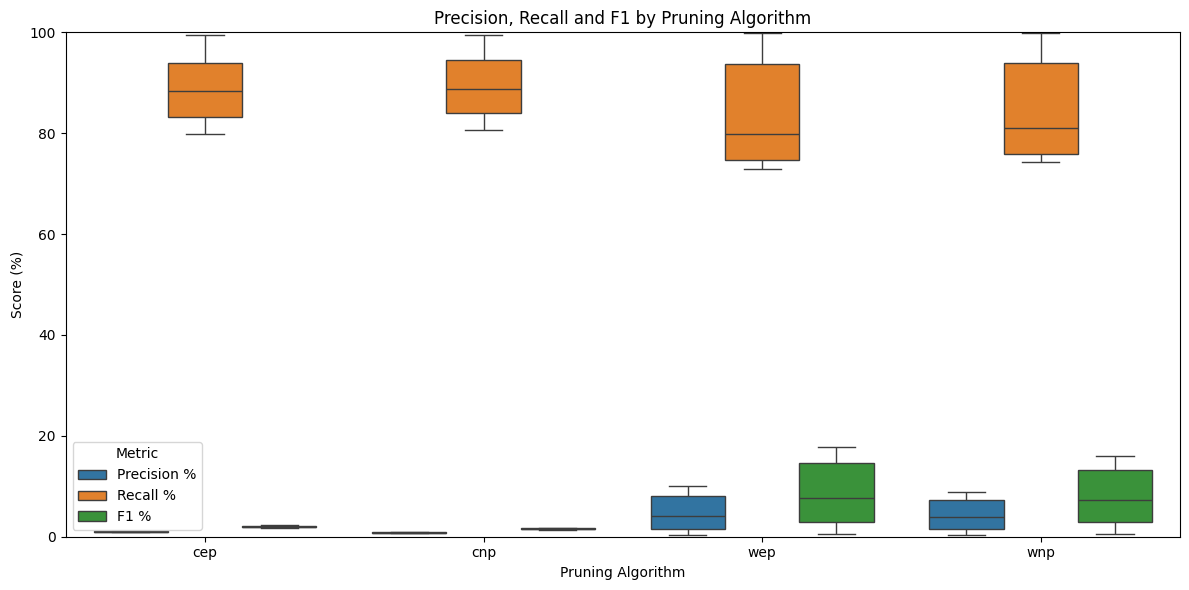

In [13]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="algorithm",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Pruning Algorithm")
plt.xlabel("Pruning Algorithm")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()